In [1]:
# [CELL 1] Mount Drive and configure paths / hyperparameters
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT      = '/content/drive/MyDrive/beta_vae_fig7'   # everything lives here
DATA_DIR  = os.path.join(ROOT, 'data')
CKPT_DIR  = os.path.join(ROOT, 'checkpoints')
CACHE_DIR = os.path.join(ROOT, 'cache')
FIG_DIR   = os.path.join(ROOT, 'figures')
for d in (DATA_DIR, CKPT_DIR, CACHE_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

CFG = dict(
    # --- From the paper (Table 1, 2D shapes VAE row; Sec. 4.2; Fig. 7 caption) ---
    n_in=4096,            # flattened 64x64x1
    n_hidden=1200,        # encoder FC 1200,1200 (ReLU); decoder FC 1200,1200,1200,4096 (Tanh)
    latent_dim=10,        # 10 latents
    lr=1e-2,              # Adagrad 1e-2
    traversal=(3.0, 1.5, 0.0, -1.5, -3.0),   # 5 rows, +3 (top) to -3 (bottom)
    # --- NOT given in the paper: my choices, change freely ---
    batch_size=64,
    num_steps=300_000,
    ckpt_every=5_000,     # how often progress is saved to Drive
    log_every=1_000,
    n_columns=6,          # 5 most informative latents + 1 uninformative ("z_unused"), as drawn in Fig. 7
    # seed image for the traversals: (shape, scale, orientation, posX, posY) class indices
    # shape: 0=square, 1=ellipse/oval, 2=heart
    seed_image=(1, 3, 5, 16, 16),
)
RUNS = {
    'A': dict(beta=4.0, seed=1, title=r'$\beta$-VAE ($\beta=4$)'),
    'B': dict(beta=1.0, seed=1, title=r'VAE ($\beta=1$)'),
}
print('Working directory on Drive:', ROOT)


Mounted at /content/drive
Working directory on Drive: /content/drive/MyDrive/beta_vae_fig7


In [2]:
# [CELL 2] Download the 2D shapes dataset into Drive (once) and build a compact cached copy
import urllib.request, time
import numpy as np

DSPRITES_URL = ('https://github.com/deepmind/dsprites-dataset/raw/master/'
                'dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz')
RAW_PATH     = os.path.join(DATA_DIR, 'dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz')
PACKED_PATH  = os.path.join(DATA_DIR, 'imgs_packed.npy')      # bit-packed images, 737280 x 512 bytes
CLASSES_PATH = os.path.join(DATA_DIR, 'latent_classes.npy')   # (shape, scale, orientation, posX, posY)

N_IMAGES = 737_280
SIZES    = (3, 6, 40, 32, 32)   # shape, scale, orientation (2*pi range), posX, posY  (Sec. 4.2)

def _raw_ok(path):
    try:
        with np.load(path, allow_pickle=True, encoding='latin1') as d:
            return {'imgs', 'latents_classes'} <= set(d.files)
    except Exception:
        return False

def _atomic_np_save(arr, path):
    tmp = path + '.tmp'
    with open(tmp, 'wb') as f:
        np.save(f, arr)
    os.replace(tmp, path)

if not (os.path.exists(RAW_PATH) and _raw_ok(RAW_PATH)):
    print('Downloading dataset into Drive ...')
    tmp = RAW_PATH + '.part'
    urllib.request.urlretrieve(DSPRITES_URL, tmp)
    os.replace(tmp, RAW_PATH)
    assert _raw_ok(RAW_PATH), 'Downloaded file is not a valid dataset archive.'
print('Raw dataset:', RAW_PATH, f'({os.path.getsize(RAW_PATH)/1e6:.1f} MB)')

if not (os.path.exists(PACKED_PATH) and os.path.exists(CLASSES_PATH)):
    print('Building packed cache (one-time, ~1 min) ...')
    with np.load(RAW_PATH, allow_pickle=True, encoding='latin1') as d:
        imgs = d['imgs']                                   # (737280, 64, 64) uint8 in {0,1}
        classes = d['latents_classes'][:, 1:].astype(np.int16)   # drop the constant colour column
    assert imgs.shape == (N_IMAGES, 64, 64) and imgs.max() == 1
    packed = np.packbits(imgs.reshape(N_IMAGES, -1), axis=1)    # (737280, 512)
    del imgs
    _atomic_np_save(classes, CLASSES_PATH)
    _atomic_np_save(packed, PACKED_PATH)
    del packed
print('Packed cache ready.')


Raw dataset: /content/drive/MyDrive/beta_vae_fig7/data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz (19.3 MB)
Building packed cache (one-time, ~1 min) ...
Packed cache ready.


In [3]:
# [CELL 3] Load data onto the GPU (re-run after every reconnect)
import torch, torch.nn as nn, torch.nn.functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'
if device == 'cpu':
    print('WARNING: no GPU. Runtime > Change runtime type > GPU, otherwise training is very slow.')

packed_np  = np.load(PACKED_PATH)
classes_np = np.load(CLASSES_PATH)

# The dataset is the full Cartesian product of the factors; the per-factor averages below
# rely on it being stored in row-major order over SIZES. Verify that.
expected = np.stack(np.unravel_index(np.arange(N_IMAGES), SIZES), axis=1)
assert (classes_np == expected).all(), 'Unexpected dataset ordering.'
del expected

X_packed = torch.from_numpy(packed_np).to(device)                 # ~377 MB
_SHIFTS  = torch.arange(7, -1, -1, device=device, dtype=torch.uint8)

def get_images(idx):
    """idx: LongTensor of image indices -> float tensor (B, 4096) with values in {0,1}."""
    p = X_packed[idx]
    return ((p.unsqueeze(-1) >> _SHIFTS) & 1).reshape(p.shape[0], -1).float()

# sanity check of the unpacking
_i = np.array([0, 12345, N_IMAGES - 1])
assert np.array_equal(get_images(torch.as_tensor(_i, device=device)).cpu().numpy().astype(np.uint8),
                      np.unpackbits(packed_np[_i], axis=1))

# Check how posX/posY map onto image axes so the position heat-maps match image space
def _centroid(i):
    im = get_images(torch.tensor([i], device=device)).cpu().numpy().reshape(64, 64)
    r, c = np.nonzero(im); return r.mean(), c.mean()
_base = lambda px, py: np.ravel_multi_index((0, 0, 0, px, py), SIZES)
r00, c00 = _centroid(_base(0, 0)); r_x, c_x = _centroid(_base(31, 0)); r_y, c_y = _centroid(_base(0, 31))
assert abs(c_x - c00) > abs(r_x - r00), 'posX is expected to move objects horizontally'
POSY_DOWN = (r_y > r00)    # True -> posY index grows downwards in the image
print(f'Device: {device}.  posX = horizontal, posY grows {"down" if POSY_DOWN else "up"}.')


Device: cuda.  posX = horizontal, posY grows down.


In [4]:
# [CELL 4] beta-VAE model and objective (Table 1 architecture, Eq. 4 objective)
class MLPBetaVAE(nn.Module):
    def __init__(self, n_in=4096, n_hidden=1200, n_latent=10):
        super().__init__()
        # Encoder: FC 1200, 1200, ReLU -> Gaussian q(z|x) = N(mu(x), sigma(x))
        self.encoder = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, 2 * n_latent))
        # Decoder: FC 1200, 1200, 1200, 4096, Tanh; Bernoulli output (logits)
        self.decoder = nn.Sequential(
            nn.Linear(n_latent, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_in))

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=-1)
        return mu, logvar

    def decode(self, z):
        return self.decoder(z)          # Bernoulli logits

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparameterisation
        return self.decode(z), mu, logvar


def beta_vae_loss(x, logits, mu, logvar, beta):
    """Negative of Eq. 4: -E_q[log p(x|z)] + beta * KL(q(z|x) || N(0, I)), averaged over the batch."""
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction='none').sum(dim=1)
    kl  = 0.5 * (mu.pow(2) + logvar.exp() - 1.0 - logvar).sum(dim=1)
    return (rec + beta * kl).mean(), rec.mean(), kl.mean()


In [5]:
# [CELL 5] Training loop with resumable checkpoints in Drive
def _atomic_torch_save(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)

def ckpt_path(run):
    return os.path.join(CKPT_DIR, f'run_{run}.pt')

def train_run(run, beta, seed, cfg=CFG):
    path = ckpt_path(run)
    torch.manual_seed(seed); np.random.seed(seed)
    model = MLPBetaVAE(cfg['n_in'], cfg['n_hidden'], cfg['latent_dim']).to(device)
    opt   = torch.optim.Adagrad(model.parameters(), lr=cfg['lr'])
    gen   = torch.Generator(device=device); gen.manual_seed(seed)
    step, history = 0, []

    if os.path.exists(path):
        ck = torch.load(path, map_location='cpu', weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        gen.set_state(ck['gen']); torch.set_rng_state(ck['cpu_rng'])
        if device == 'cuda' and ck.get('cuda_rng') is not None:
            torch.cuda.set_rng_state(ck['cuda_rng'])
        step, history = ck['step'], ck['history']
        assert ck['beta'] == beta and ck['seed'] == seed, \
            f'{path} was trained with beta={ck["beta"]}, seed={ck["seed"]}; delete it to start over.'
        print(f'[{run}] resumed from step {step}')

    def save():
        _atomic_torch_save(dict(
            model=model.state_dict(), opt=opt.state_dict(), gen=gen.get_state(),
            cpu_rng=torch.get_rng_state(),
            cuda_rng=torch.cuda.get_rng_state() if device == 'cuda' else None,
            step=step, history=history, beta=beta, seed=seed), path)

    model.train()
    acc = torch.zeros(3, device=device); t0 = time.time()
    while step < cfg['num_steps']:
        idx = torch.randint(0, N_IMAGES, (cfg['batch_size'],), device=device, generator=gen)
        x = get_images(idx)
        logits, mu, logvar = model(x)
        loss, rec, kl = beta_vae_loss(x, logits, mu, logvar, beta)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        step += 1
        acc += torch.stack([loss.detach(), rec.detach(), kl.detach()])

        if step % cfg['log_every'] == 0:
            l, r, k = (acc / cfg['log_every']).tolist(); acc.zero_()
            if not np.isfinite(l):
                raise RuntimeError(f'[{run}] loss diverged at step {step}. Delete {path} '
                                   'and re-run with a different seed in RUNS.')
            history.append((step, l, r, k))
            print(f'[{run}] step {step:>7d} | loss {l:8.2f} | recon {r:8.2f} | KL {k:6.2f} '
                  f'| {cfg["log_every"]/(time.time()-t0):6.0f} it/s')
            t0 = time.time()
        if step % cfg['ckpt_every'] == 0 or step == cfg['num_steps']:
            save()
    model.eval()
    return model, step


In [6]:
# [CELL 6] Train both models (re-run after a disconnect: it resumes from the last checkpoint)
models, trained_steps = {}, {}
for run, spec in RUNS.items():
    models[run], trained_steps[run] = train_run(run, spec['beta'], spec['seed'])
    print(f'[{run}] done ({trained_steps[run]} steps)\n')


[A] step    1000 | loss   340.89 | recon   256.43 | KL  21.11 |    186 it/s
[A] step    2000 | loss   169.97 | recon   130.41 | KL   9.89 |    209 it/s
[A] step    3000 | loss   158.87 | recon   120.90 | KL   9.49 |    210 it/s
[A] step    4000 | loss   153.00 | recon   117.13 | KL   8.97 |    190 it/s
[A] step    5000 | loss   148.22 | recon   114.07 | KL   8.54 |    210 it/s
[A] step    6000 | loss   146.03 | recon   112.19 | KL   8.46 |    199 it/s
[A] step    7000 | loss   145.17 | recon   111.31 | KL   8.47 |    209 it/s
[A] step    8000 | loss   144.36 | recon   110.41 | KL   8.49 |    207 it/s
[A] step    9000 | loss   143.48 | recon   109.32 | KL   8.54 |    208 it/s
[A] step   10000 | loss   142.37 | recon   107.83 | KL   8.63 |    207 it/s
[A] step   11000 | loss   141.55 | recon   106.51 | KL   8.76 |    195 it/s
[A] step   12000 | loss   139.72 | recon   104.15 | KL   8.89 |    205 it/s
[A] step   13000 | loss   138.69 | recon   102.67 | KL   9.00 |    205 it/s
[A] step   1

In [7]:
# [CELL 7] Encode the whole dataset with each model (cached in Drive)
@torch.no_grad()
def encode_all(run, model, step, chunk=8192):
    path = os.path.join(CACHE_DIR, f'encodings_{run}.npz')
    if os.path.exists(path):
        with np.load(path) as d:
            if int(d['step']) == step:
                return d['mu'], d['logvar']
    model.eval()
    mus, lvs = [], []
    for s in range(0, N_IMAGES, chunk):
        idx = torch.arange(s, min(s + chunk, N_IMAGES), device=device)
        mu, lv = model.encode(get_images(idx))
        mus.append(mu.cpu().numpy()); lvs.append(lv.cpu().numpy())
    mu, lv = np.concatenate(mus), np.concatenate(lvs)
    tmp = path + '.tmp'
    with open(tmp, 'wb') as f:
        np.savez(f, mu=mu, logvar=lv, step=step)
    os.replace(tmp, path)
    return mu, lv

encodings = {run: encode_all(run, models[run], trained_steps[run]) for run in RUNS}
print('Encodings ready:', {r: e[0].shape for r, e in encodings.items()})


Encodings ready: {'A': (737280, 10), 'B': (737280, 10)}


In [8]:
# [CELL 8] Statistics behind each Fig. 7 panel
FACTOR_NAMES = ['shape', 'scale', 'rotation', 'pos. X', 'pos. Y']

def compute_panel_stats(mu, logvar, n_columns=CFG['n_columns']):
    M = mu.shape[1]
    g = mu.reshape(*SIZES, M)                      # (shape, scale, rot, posX, posY, M)

    # Row 1: mean of mu_i over all 32x32 positions, averaged across objects, rotations, scales
    pos = g.mean(axis=(0, 1, 2)).transpose(1, 0, 2)    # -> (posY rows, posX cols, M)
    if not POSY_DOWN:
        pos = pos[::-1]
    # Row 2: mean of mu_i vs scale, per shape, averaged over rotations and positions
    scale = g.mean(axis=(2, 3, 4))                 # (3, 6, M)
    # Row 3: mean of mu_i vs rotation, per shape, averaged over scales and positions
    rot = g.mean(axis=(1, 3, 4))                   # (3, 40, M)
    # Last row: learnt Gaussian variance sigma^2, averaged over the dataset
    var = np.exp(logvar).astype(np.float64).mean(axis=0)

    # Column order (Fig. 7): latents sorted by learnt variance (most informative first),
    # plus the most uninformative latent as the last column.
    order = np.argsort(var)
    cols = list(order[:n_columns - 1]) + [order[-1]]

    # Factor labels under each column. The paper labelled these by hand; this is a simple
    # automatic stand-in (not from the paper): fraction of the variance of mu_i explained
    # by each factor (rotation allowed to interact with shape, because of symmetries).
    total = g.reshape(-1, M).var(axis=0) + 1e-12
    v_shape = g.mean(axis=(1, 2, 3, 4)).var(axis=0)
    explained = [v_shape]
    for ax in (1, 2, 3, 4):
        other = tuple(a for a in (1, 2, 3, 4) if a != ax)
        explained.append(g.mean(axis=other).reshape(-1, M).var(axis=0) - v_shape)
    frac = np.stack(explained) / total             # (5 factors, M)
    labels = []
    for i in range(M):
        if var[i] > 0.9:
            labels.append('')
        elif frac[:, i].max() >= 0.5:
            labels.append(FACTOR_NAMES[int(frac[:, i].argmax())])
        else:
            labels.append('mixed')
    return dict(pos=pos, scale=scale, rot=rot, var=var, cols=cols, labels=labels, frac=frac)

stats = {}
for run in RUNS:
    path = os.path.join(CACHE_DIR, f'stats_{run}_step{trained_steps[run]}.npz')
    if os.path.exists(path):
        with np.load(path, allow_pickle=True) as d:
            stats[run] = {k: d[k] for k in d.files}
            stats[run]['cols'] = list(stats[run]['cols']); stats[run]['labels'] = list(stats[run]['labels'])
    else:
        stats[run] = compute_panel_stats(*encodings[run])
        tmp = path + '.tmp'
        with open(tmp, 'wb') as f:
            np.savez(f, **{k: np.asarray(v) for k, v in stats[run].items()})
        os.replace(tmp, path)
    s = stats[run]
    print(f'[{run}] columns (0-based latent idx): {s["cols"]}')
    for i in s['cols']:
        print(f'   z{i+1:<2d} var={s["var"][i]:.2f}  ' +
              '  '.join(f'{n}={f:.2f}' for n, f in zip(FACTOR_NAMES, s['frac'][:, i])))


[A] columns (0-based latent idx): [np.int64(6), np.int64(5), np.int64(2), np.int64(9), np.int64(1), np.int64(4)]
   z7  var=0.00  shape=0.00  scale=0.00  rotation=0.00  pos. X=0.88  pos. Y=0.01
   z6  var=0.00  shape=0.00  scale=0.00  rotation=0.00  pos. X=0.01  pos. Y=0.92
   z3  var=0.01  shape=0.06  scale=0.28  rotation=0.00  pos. X=0.29  pos. Y=0.21
   z10 var=0.12  shape=0.00  scale=0.00  rotation=0.57  pos. X=0.00  pos. Y=0.00
   z2  var=0.13  shape=0.00  scale=0.00  rotation=0.10  pos. X=0.00  pos. Y=0.00
   z5  var=0.99  shape=0.00  scale=0.01  rotation=0.01  pos. X=0.01  pos. Y=0.02
[B] columns (0-based latent idx): [np.int64(5), np.int64(6), np.int64(2), np.int64(0), np.int64(1), np.int64(9)]
   z6  var=0.00  shape=0.00  scale=0.00  rotation=0.01  pos. X=0.47  pos. Y=0.40
   z7  var=0.00  shape=0.00  scale=0.01  rotation=0.00  pos. X=0.50  pos. Y=0.36
   z3  var=0.00  shape=0.04  scale=0.11  rotation=0.00  pos. X=0.28  pos. Y=0.46
   z1  var=0.01  shape=0.01  scale=0.01  rota

In [9]:
# [CELL 9] Latent traversals (rows 4-8): one latent swept over [+3, -3], others fixed
@torch.no_grad()
def traversal_images(model, mu_all, cols, values=CFG['traversal'], seed_image=CFG['seed_image']):
    z0 = mu_all[np.ravel_multi_index(seed_image, SIZES)]
    Z = np.repeat(z0[None, None], len(values), 0).repeat(len(cols), 1)    # (rows, cols, M)
    for c, i in enumerate(cols):
        Z[:, c, i] = values
    z = torch.as_tensor(Z.reshape(-1, Z.shape[-1]), dtype=torch.float32, device=device)
    imgs = torch.sigmoid(model.decode(z)).cpu().numpy()
    return imgs.reshape(len(values), len(cols), 64, 64)

traversals = {run: traversal_images(models[run], encodings[run][0], stats[run]['cols']) for run in RUNS}


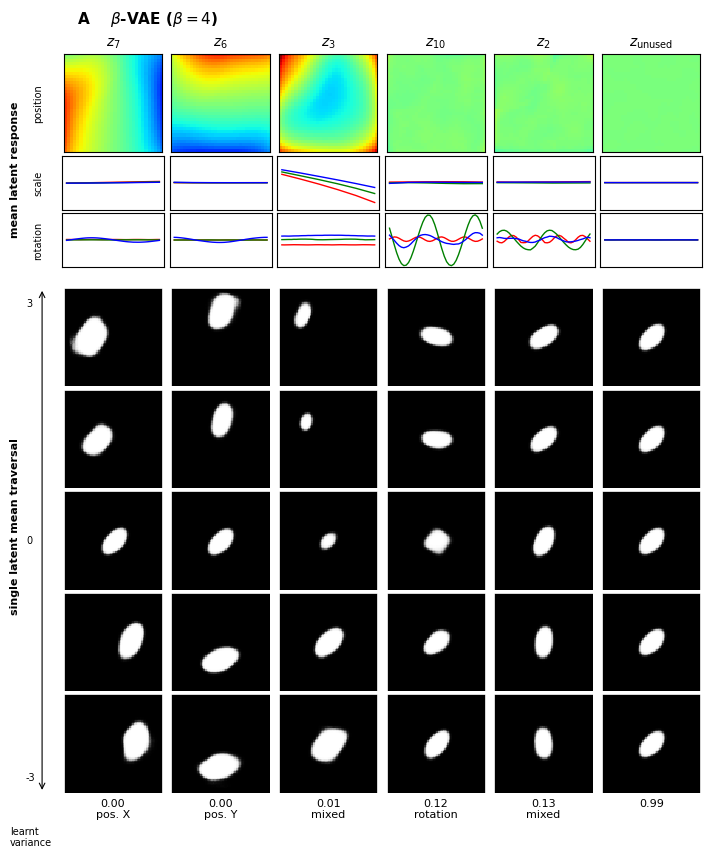

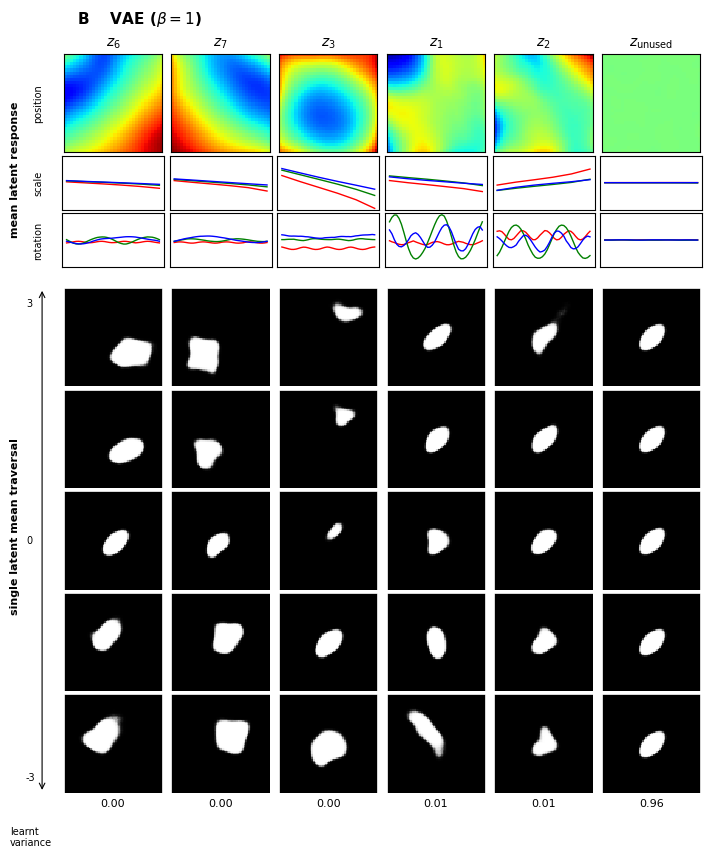

Saved to /content/drive/MyDrive/beta_vae_fig7/figures


In [10]:
# [CELL 10] Draw Fig. 7A and Fig. 7B and save them to Drive
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

SHAPE_COLOURS = ['red', 'green', 'blue']     # square, oval, heart (Fig. 7 caption)

def plot_panel(letter, title, s, trav, show_labels=True, values=CFG['traversal']):
    cols = s['cols']; n = len(cols); R = len(values)
    fig = plt.figure(figsize=(1.0 * n + 1.1, 1.0 * (R + 1) + 2.9))
    gs = GridSpec(4 + R, n + 1, figure=fig,
                  height_ratios=[1, 0.55, 0.55, 0.15] + [1] * R,
                  width_ratios=[0.35] + [1] * n, hspace=0.04, wspace=0.06,
                  left=0.02, right=0.98, top=0.93, bottom=0.10)

    pos_lim = np.abs(s['pos'][..., cols]).max()
    line_lim = 1.05 * max(np.abs(s['scale'][..., cols]).max(), np.abs(s['rot'][..., cols]).max())

    for c, i in enumerate(cols):
        unused = (c == n - 1 and s['var'][i] > 0.9)
        head = r'$z_{\mathrm{unused}}$' if unused else f'$z_{{{i+1}}}$'

        ax = fig.add_subplot(gs[0, c + 1])
        ax.imshow(s['pos'][..., i], cmap='jet', vmin=-pos_lim, vmax=pos_lim, interpolation='nearest')
        ax.set_title(head, fontsize=10); ax.set_xticks([]); ax.set_yticks([])

        ax = fig.add_subplot(gs[1, c + 1])
        for sh in range(3):
            ax.plot(s['scale'][sh, :, i], color=SHAPE_COLOURS[sh], lw=1)
        ax.set_ylim(-line_lim, line_lim); ax.set_xticks([]); ax.set_yticks([])

        ax = fig.add_subplot(gs[2, c + 1])
        for sh in range(3):
            ax.plot(s['rot'][sh, :, i], color=SHAPE_COLOURS[sh], lw=1)
        ax.set_ylim(-line_lim, line_lim); ax.set_xticks([]); ax.set_yticks([])

        for r in range(R):
            ax = fig.add_subplot(gs[4 + r, c + 1])
            ax.imshow(trav[r, c], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_edgecolor('white'); sp.set_linewidth(0.6)
            if r == R - 1:
                lab = s['labels'][i] if show_labels else ''
                ax.set_xlabel(f'{s["var"][i]:.2f}\n{lab}', fontsize=8)

    # row labels
    for r, name in enumerate(['position', 'scale', 'rotation']):
        ax = fig.add_subplot(gs[r, 0]); ax.axis('off')
        ax.text(0.5, 0.5, name, rotation=90, ha='center', va='center', fontsize=7)
    ax = fig.add_subplot(gs[4:, 0]); ax.axis('off')
    ax.annotate('', xy=(0.6, 1.0), xytext=(0.6, 0.0), xycoords='axes fraction',
                arrowprops=dict(arrowstyle='<->', lw=0.8))
    ax.text(0.15, 0.98, f'{values[0]:g}', fontsize=7, va='top')
    ax.text(0.15, 0.5, '0', fontsize=7, va='center')
    ax.text(0.15, 0.02, f'{values[-1]:g}', fontsize=7, va='bottom')
    fig.text(0.005, 0.80, 'mean latent response', rotation=90, fontsize=8, weight='bold', va='center')
    fig.text(0.005, 0.40, 'single latent mean traversal', rotation=90, fontsize=8, weight='bold', va='center')
    fig.text(0.005, 0.05, 'learnt\nvariance', fontsize=7, va='center')
    fig.suptitle(f'{letter}    {title}', x=0.1, ha='left', fontsize=11, weight='bold')
    return fig

for run, spec in RUNS.items():
    fig = plot_panel(run, spec['title'], stats[run], traversals[run], show_labels=(run == 'A'))
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIG_DIR, f'fig7{run}.{ext}'), dpi=200, bbox_inches='tight')
    plt.show()
print('Saved to', FIG_DIR)
